# 02 — Electricity Consumption EDA (2019–2023)

2019–2023: distributions, trend, detrending, seasonality, calendar heatmaps, and MSTL decomposition.
2024 is excluded and held out for final evaluation. All plots use average load in MW.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LinearRegression

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "pyproject.toml").exists() and (p / "data").is_dir()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run from inside the electricity-reg-germany repository.")

TARGET = "Netzlast [MWh] Berechnete Auflösungen"
TIMEZONE = "Europe/Berlin"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

## Phase 1 — Prepare the data

- Read hourly and daily CSVs; keep 2019–2023.
- Parse German numbers and localize timestamps to `Europe/Berlin`.
- Add `year`, `month`, `hour`, `weekday`, `day_type` (Weekday/Weekend), `season` (used in Phase 4), and `time_years` (used for the linear trend in Phase 3).
- Average load (MW) = consumption (MWh) / actual hours: 1 hourly; 23, 24 or 25 daily.

In [2]:
analysis = {}
for resolution, suffix in [("hourly", "Stunde"), ("daily", "Tag")]:
    path = ROOT / "data" / (f"Realisierter_Stromverbrauch_201901010000_202501010000_{suffix}.csv")
    raw = pd.read_csv(path, sep=";", encoding="utf-8-sig", dtype=str)
    fmt = "%d.%m.%Y %H:%M" if resolution == "hourly" else "%d.%m.%Y"
    local = pd.to_datetime(raw["Datum von"], format=fmt, errors="raise")
    selected = (local >= "2019-01-01") & (local < "2024-01-01")
    local = local.loc[selected]
    values = raw.loc[selected, TARGET].str.strip().str.replace(".", "", regex=False)
    values = pd.to_numeric(values.str.replace(",", ".", regex=False), errors="raise")
    if not np.isfinite(values).all() or values.le(0).any():
        raise ValueError(f"{resolution}: investigate invalid consumption before continuing.")
    aware = pd.DatetimeIndex(local).tz_localize(TIMEZONE, ambiguous="infer", nonexistent="raise")
    frame = pd.DataFrame({"start_local": aware, "consumption_mwh": values.to_numpy()})
    local_dates = aware.tz_localize(None).normalize()
    frame["local_date"] = local_dates
    frame["year"] = aware.year
    frame["month"] = aware.month
    frame["hour"] = aware.hour
    frame["weekday"] = aware.day_of_week
    frame["day_type"] = np.where(frame["weekday"] < 5, "Weekday", "Weekend")
    season_map = {
        12: "Winter",
        1: "Winter",
        2: "Winter",
        3: "Spring",
        4: "Spring",
        5: "Spring",
        6: "Summer",
        7: "Summer",
        8: "Summer",
        9: "Autumn",
        10: "Autumn",
        11: "Autumn",
    }
    frame["season"] = frame["month"].map(season_map)
    frame["time_years"] = (local_dates - pd.Timestamp("2019-01-01")).days / 365.25
    if resolution == "daily":
        next_midnight = (local_dates + pd.Timedelta(days=1)).tz_localize(TIMEZONE)
        frame["interval_hours"] = (next_midnight - aware).total_seconds() / 3600
    else:
        frame["interval_hours"] = 1.0
    frame["average_load_mw"] = frame["consumption_mwh"] / frame["interval_hours"]
    analysis[resolution] = frame
    print(f"{resolution}: {len(frame):,} observations, {local.min()} to {local.max()}")
    display(analysis[resolution].head(7))
hourly, daily = analysis["hourly"], analysis["daily"]

hourly: 43,824 observations, 2019-01-01 00:00:00 to 2023-12-31 23:00:00


,start_local,consumption_mwh,local_date,year,month,hour,weekday,day_type,season,time_years,interval_hours,average_load_mw
0,2019-01-01 00:00:00+01:00,43273.75,2019-01-01,2019,1,0,1,Weekday,Winter,0.0,1.0,43273.75
1,2019-01-01 01:00:00+01:00,41631.25,2019-01-01,2019,1,1,1,Weekday,Winter,0.0,1.0,41631.25
2,2019-01-01 02:00:00+01:00,40085.00,2019-01-01,2019,1,2,1,Weekday,Winter,0.0,1.0,40085.00
3,2019-01-01 03:00:00+01:00,39269.75,2019-01-01,2019,1,3,1,Weekday,Winter,0.0,1.0,39269.75
4,2019-01-01 04:00:00+01:00,39032.75,2019-01-01,2019,1,4,1,Weekday,Winter,0.0,1.0,39032.75
5,2019-01-01 05:00:00+01:00,38570.50,2019-01-01,2019,1,5,1,Weekday,Winter,0.0,1.0,38570.50
6,2019-01-01 06:00:00+01:00,38047.50,2019-01-01,2019,1,6,1,Weekday,Winter,0.0,1.0,38047.50


daily: 1,826 observations, 2019-01-01 00:00:00 to 2023-12-31 00:00:00


,start_local,consumption_mwh,local_date,year,month,hour,weekday,day_type,season,time_years,interval_hours,average_load_mw
0,2019-01-01 00:00:00+01:00,1097118.75,2019-01-01,2019,1,0,1,Weekday,Winter,0.000000,24.0,45713.281250
1,2019-01-02 00:00:00+01:00,1388494.25,2019-01-02,2019,1,0,2,Weekday,Winter,0.002738,24.0,57853.927083
2,2019-01-03 00:00:00+01:00,1466308.25,2019-01-03,2019,1,0,3,Weekday,Winter,0.005476,24.0,61096.177083
3,2019-01-04 00:00:00+01:00,1486876.25,2019-01-04,2019,1,0,4,Weekday,Winter,0.008214,24.0,61953.177083
4,2019-01-05 00:00:00+01:00,1315755.00,2019-01-05,2019,1,0,5,Weekend,Winter,0.010951,24.0,54823.125000
5,2019-01-06 00:00:00+01:00,1207037.75,2019-01-06,2019,1,0,6,Weekend,Winter,0.013689,24.0,50293.239583
6,2019-01-07 00:00:00+01:00,1525289.00,2019-01-07,2019,1,0,0,Weekday,Winter,0.016427,24.0,63553.708333


## Phase 2 — Distributions

Histograms (with KDE and mean) show the overall hourly and daily load distributions. Boxplots compare average load by hour, weekday/weekend, weekday, month and year.

- Middle line: median. Box: middle 50% of values.
- Dots: values outside the whiskers; not confirmed errors.
- The last line plot compares weekday and weekend median hourly profiles.

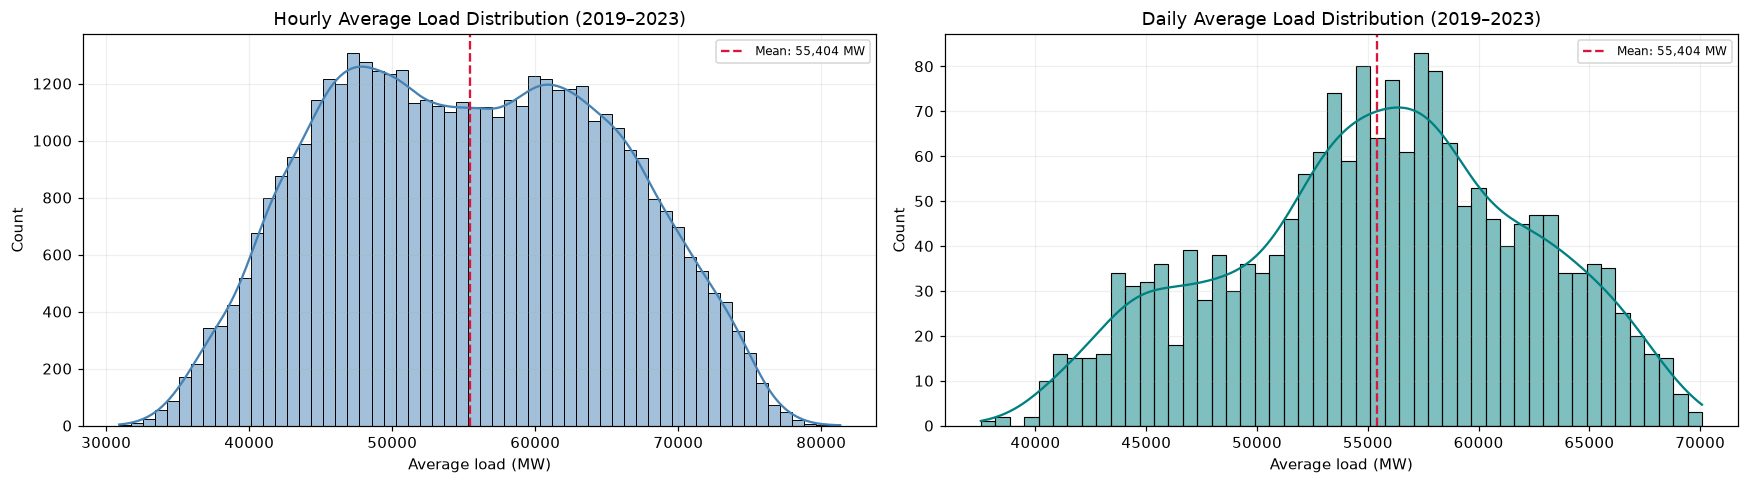

In [3]:
SEASON_ORDER = ["Winter", "Spring", "Summer", "Autumn"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

sns.histplot(hourly["average_load_mw"], bins=60, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(
    hourly["average_load_mw"].mean(),
    color="crimson",
    ls="--",
    lw=1.5,
    label=f"Mean: {hourly['average_load_mw'].mean():,.0f} MW",
)
axes[0].set_title("Hourly Average Load Distribution (2019–2023)")
axes[0].set_xlabel("Average load (MW)")
axes[0].legend(fontsize=8)

sns.histplot(daily["average_load_mw"], bins=50, kde=True, color="teal", ax=axes[1])
axes[1].axvline(
    daily["average_load_mw"].mean(),
    color="crimson",
    ls="--",
    lw=1.5,
    label=f"Mean: {daily['average_load_mw'].mean():,.0f} MW",
)
axes[1].set_title("Daily Average Load Distribution (2019–2023)")
axes[1].set_xlabel("Average load (MW)")
axes[1].legend(fontsize=8)


plt.tight_layout()
plt.show()

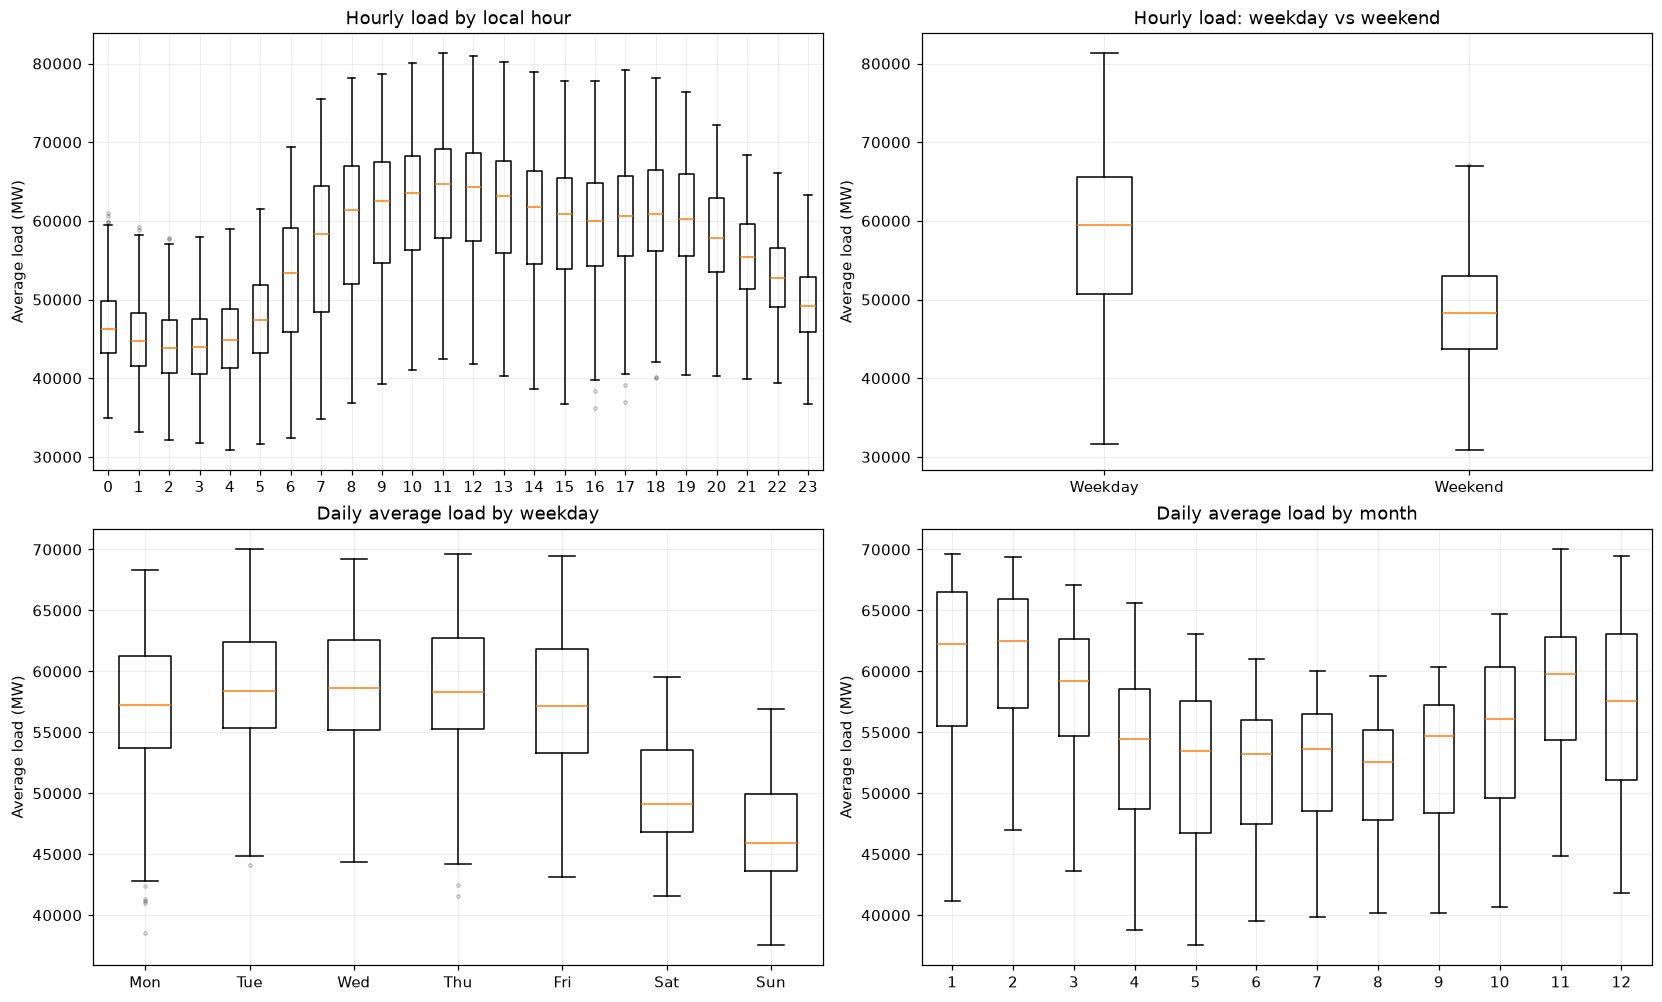

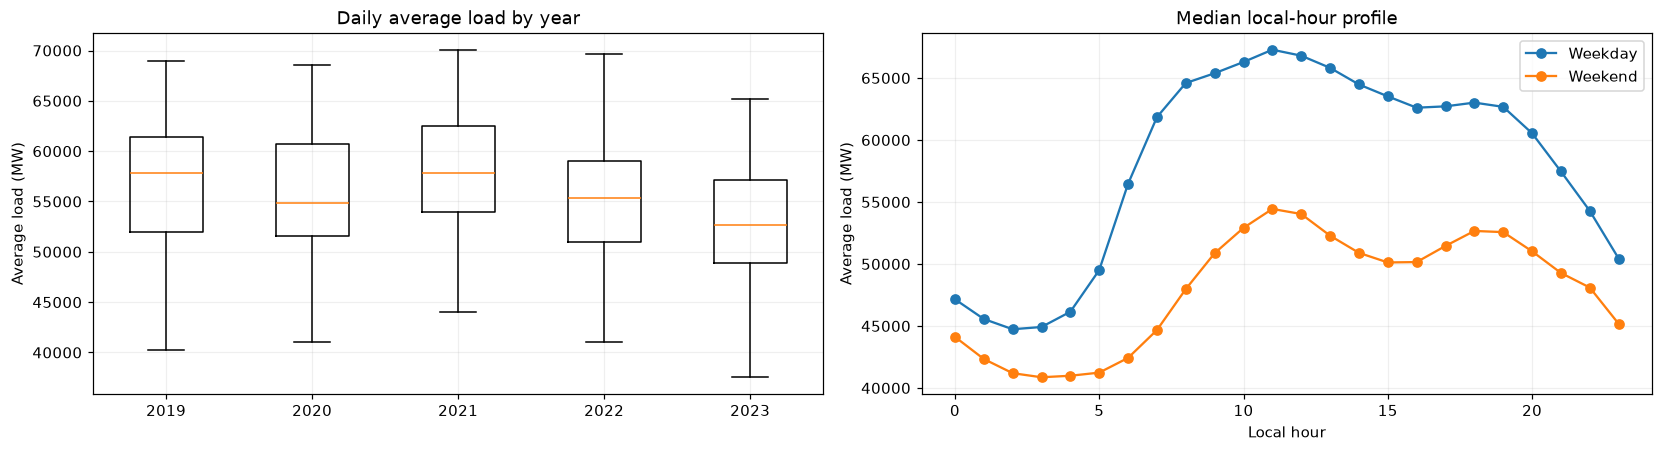

In [4]:
def calendar_boxplot(ax, frame, group, order, labels, title):
    samples = [frame.loc[frame[group].eq(value), "average_load_mw"].to_numpy() for value in order]
    ax.boxplot(
        samples, tick_labels=labels, showfliers=True, flierprops={"markersize": 2, "alpha": 0.25}
    )
    ax.set(title=title, ylabel="Average load (MW)")


fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
calendar_boxplot(axes[0, 0], hourly, "hour", range(24), range(24), "Hourly load by local hour")
calendar_boxplot(
    axes[0, 1],
    hourly,
    "day_type",
    ["Weekday", "Weekend"],
    ["Weekday", "Weekend"],
    "Hourly load: weekday vs weekend",
)
calendar_boxplot(
    axes[1, 0],
    daily,
    "weekday",
    range(7),
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    "Daily average load by weekday",
)
calendar_boxplot(
    axes[1, 1], daily, "month", range(1, 13), range(1, 13), "Daily average load by month"
)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
calendar_boxplot(
    axes[0], daily, "year", range(2019, 2024), range(2019, 2024), "Daily average load by year"
)
for kind, group in hourly.groupby("day_type"):
    axes[1].plot(group.groupby("hour")["average_load_mw"].median(), marker="o", label=kind)
axes[1].set(title="Median local-hour profile", xlabel="Local hour", ylabel="Average load (MW)")
axes[1].legend()
plt.show()

## Phase 3 — Trend

- Top-left: observed daily average load (gray) with centered 31-day (blue) and 91-day (red) rolling means.
- Top-right: monthly mean of daily average load.
- Table: yearly averages and change from the previous year.
- Bottom-left: daily load with 30-day rolling mean and global linear trend (2019–2023).
- Bottom-right: detrended daily load residuals around zero.

Rolling means reduce short-term fluctuations but still contain annual seasonality. Centered windows use past and future observations; this is descriptive analysis.

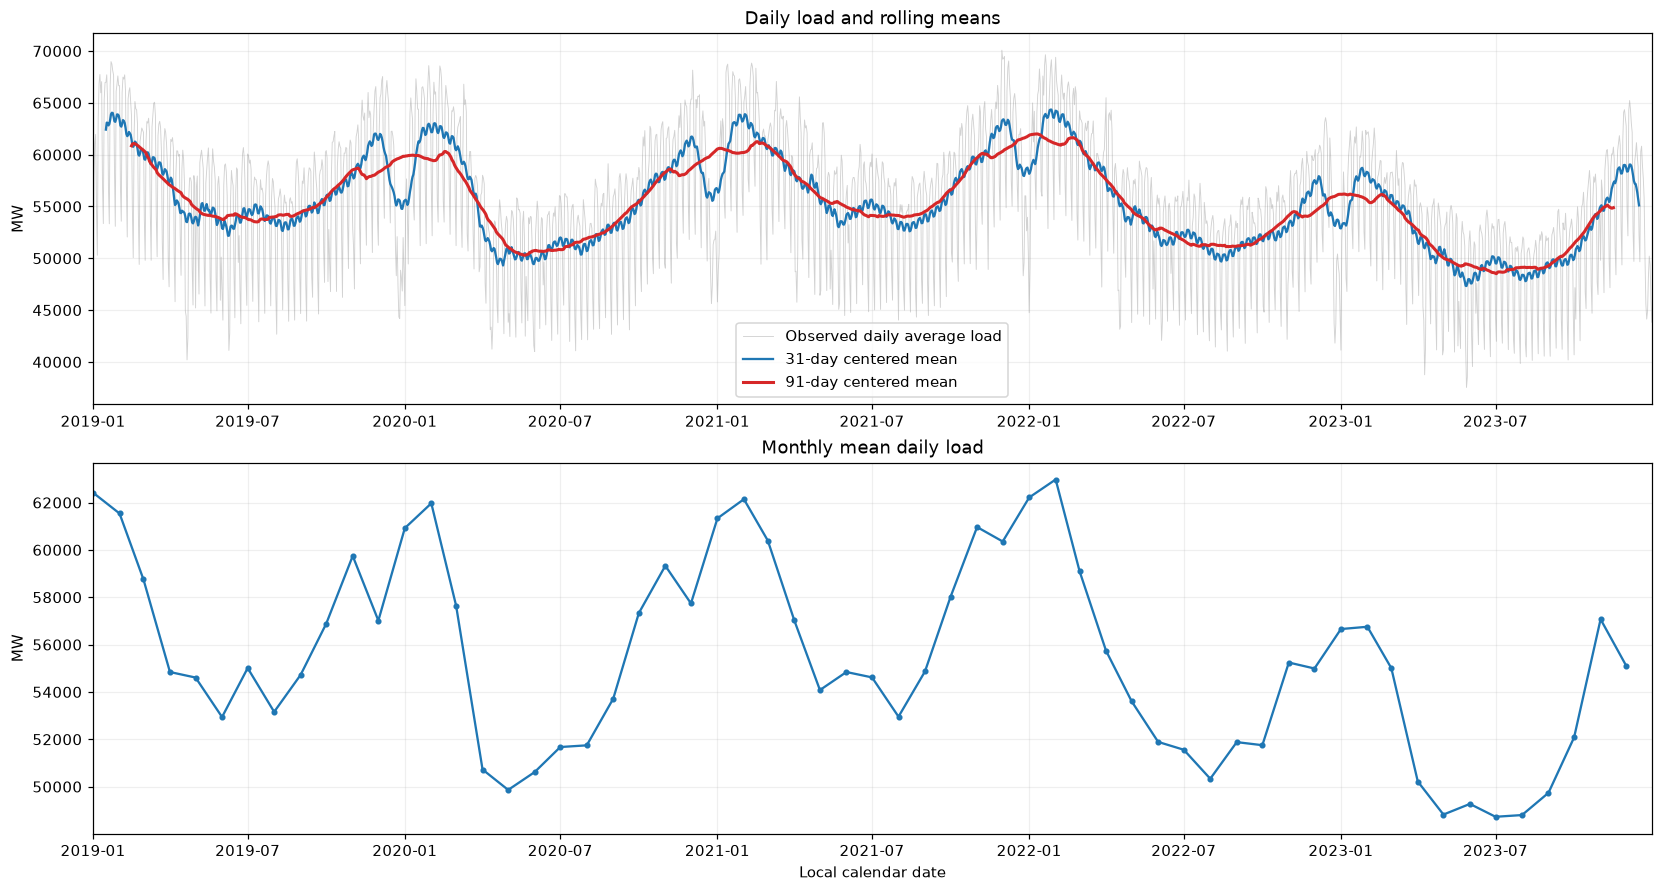

,days,mean_daily_load_mw,median_daily_load_mw,mean_change_vs_previous_year_percent
year,,,,
2019,365,56776.92,57838.02,NaN
2020,366,55254.67,54882.48,-2.68
2021,365,57603.10,57801.35,4.25
2022,365,55057.19,55311.33,-4.42
2023,365,52326.58,52642.18,-4.96


In [5]:
daily_load = pd.Series(
    daily["average_load_mw"].to_numpy(),
    index=pd.DatetimeIndex(daily["local_date"]),
    name="daily_average_load_mw",
).sort_index()
expected_dates = pd.date_range("2019-01-01", "2023-12-31", freq="D")
if not daily_load.index.equals(expected_dates) or not np.isfinite(daily_load).all():
    raise ValueError("Trend analysis requires complete, ordered local daily observations.")
daily_load = daily_load.asfreq("D")
trend_smoothers = pd.DataFrame({"observed_mw": daily_load})
trend_smoothers["rolling_31_days_mw"] = daily_load.rolling(31, center=True).mean()
trend_smoothers["rolling_91_days_mw"] = daily_load.rolling(91, center=True).mean()
monthly_average_load = daily_load.resample("MS").mean()

fig, axes = plt.subplots(2, 1, figsize=(15, 8), constrained_layout=True)
axes[0].plot(
    daily_load.index,
    daily_load,
    color="gray",
    alpha=0.35,
    linewidth=0.6,
    label="Observed daily average load",
)
axes[0].plot(
    trend_smoothers.index,
    trend_smoothers.rolling_31_days_mw,
    label="31-day centered mean",
    color="tab:blue",
)
axes[0].plot(
    trend_smoothers.index,
    trend_smoothers.rolling_91_days_mw,
    label="91-day centered mean",
    color="tab:red",
    linewidth=2,
)
axes[0].set(title="Daily load and rolling means", ylabel="MW")
axes[0].legend()
axes[1].plot(monthly_average_load.index, monthly_average_load, marker="o", markersize=3)
axes[1].set(title="Monthly mean daily load", xlabel="Local calendar date", ylabel="MW")
for ax in axes:
    ax.set_xlim(daily_load.index.min(), daily_load.index.max())
plt.show()

yearly_load_summary = daily.groupby("year").agg(
    days=("average_load_mw", "size"),
    mean_daily_load_mw=("average_load_mw", "mean"),
    median_daily_load_mw=("average_load_mw", "median"),
)
yearly_load_summary["mean_change_vs_previous_year_percent"] = (
    yearly_load_summary["mean_daily_load_mw"].pct_change() * 100
)
display(yearly_load_summary.round(2))

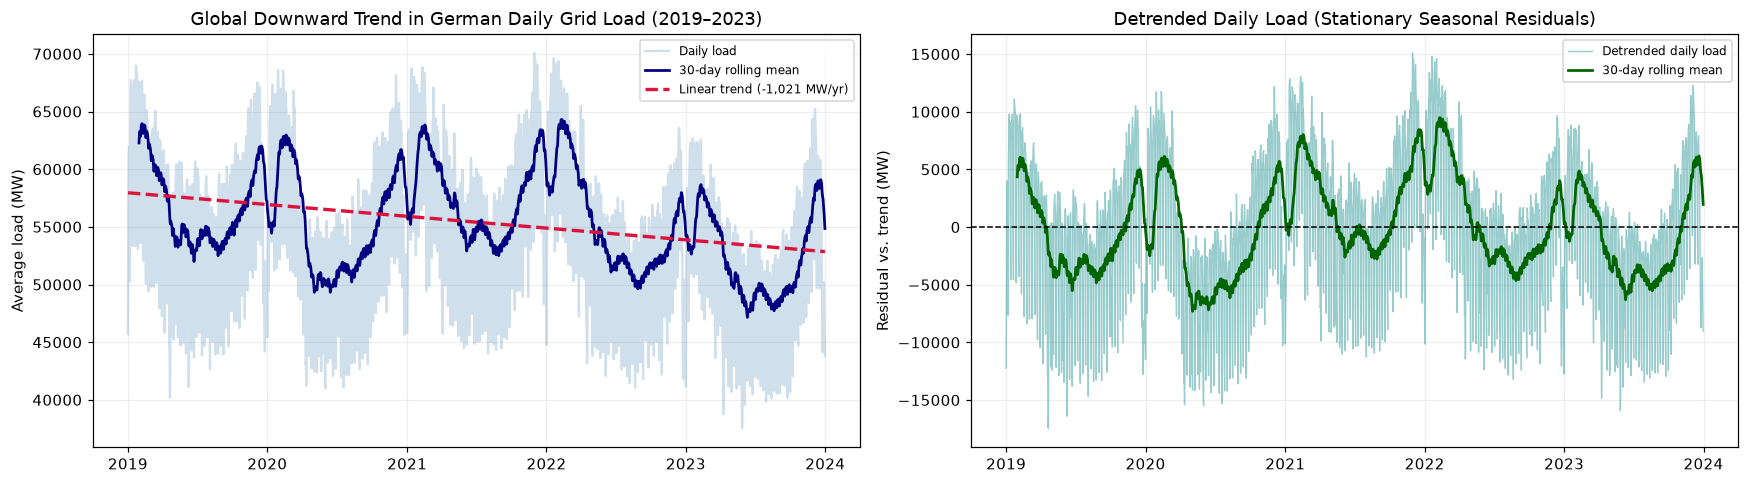

In [6]:
trend_reg = LinearRegression().fit(daily[["time_years"]], daily["average_load_mw"])
daily["linear_trend_mw"] = trend_reg.predict(daily[["time_years"]])
daily["detrended_mw"] = daily["average_load_mw"] - daily["linear_trend_mw"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].plot(
    daily["local_date"], daily["average_load_mw"], alpha=0.25, color="steelblue", label="Daily load"
)
axes[0].plot(
    daily["local_date"],
    daily["average_load_mw"].rolling(30).mean(),
    color="navy",
    lw=1.8,
    label="30-day rolling mean",
)
axes[0].plot(
    daily["local_date"],
    daily["linear_trend_mw"],
    color="crimson",
    lw=2.2,
    ls="--",
    label=f"Linear trend ({trend_reg.coef_[0]:,.0f} MW/yr)",
)
axes[0].set_title("Global Downward Trend in German Daily Grid Load (2019–2023)")
axes[0].set_ylabel("Average load (MW)")
axes[0].legend(fontsize=8)

axes[1].plot(
    daily["local_date"],
    daily["detrended_mw"],
    alpha=0.4,
    color="teal",
    lw=0.9,
    label="Detrended daily load",
)
axes[1].plot(
    daily["local_date"],
    daily["detrended_mw"].rolling(30).mean(),
    color="darkgreen",
    lw=1.8,
    label="30-day rolling mean",
)
axes[1].axhline(0, color="black", ls="--", lw=1)
axes[1].set_title("Detrended Daily Load (Stationary Seasonal Residuals)")
axes[1].set_ylabel("Residual vs. trend (MW)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Phase 4 — Seasonality

| Plot | Calculation |
|---|---|
| Hourly profile (YoY) | Mean load at each local hour, separately for each year |
| Weekly profile | Mean daily load by weekday, separately for each year |
| Annual profile | Monthly mean daily load minus that year's mean |
| Weekday × hour heatmap | Mean hourly load for each weekday/hour combination |
| Weekday hourly profile by season | Mean hourly weekday load grouped by meteorological season |
| Monthly mean daily load (YoY) | Uncentered monthly mean daily load for each year |
| Month × hour heatmap | Mean hourly weekday load for each month/hour combination |
| Month × weekday heatmap | Mean daily load for each month/weekday combination |

The annual profile compares seasonal shape after removing each year's average level. Holidays and weather are not accounted for.

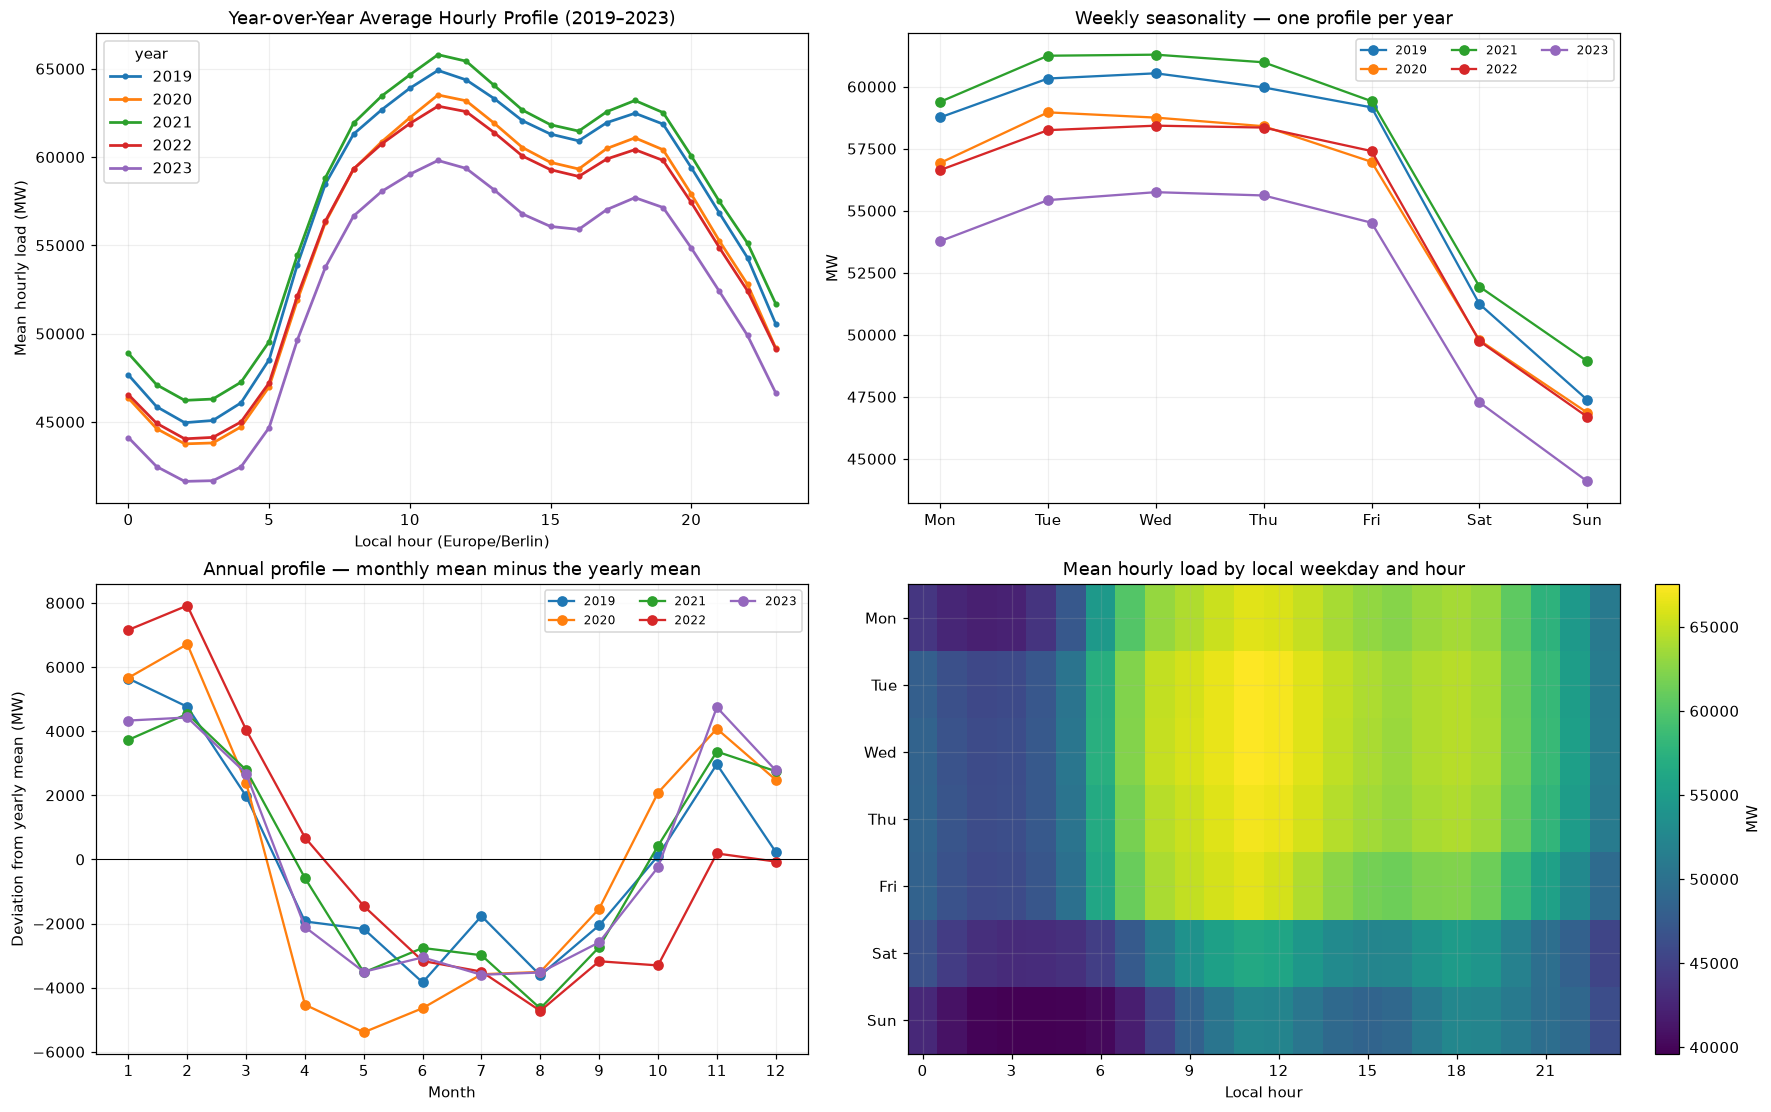

In [7]:
weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)

hourly.pivot_table(index="hour", columns="year", values="average_load_mw", aggfunc="mean").plot(
    ax=axes[0, 0], marker="o", ms=3, lw=1.8
)
axes[0, 0].set_title("Year-over-Year Average Hourly Profile (2019–2023)")
axes[0, 0].set_xlabel("Local hour (Europe/Berlin)")
axes[0, 0].set_ylabel("Mean hourly load (MW)")

for year, group in daily.groupby("year"):
    weekly_profile = group.groupby("weekday")["average_load_mw"].mean()
    axes[0, 1].plot(weekly_profile.index, weekly_profile, marker="o", label=str(year))
    monthly_profile = group.groupby("month")["average_load_mw"].mean()
    axes[1, 0].plot(
        monthly_profile.index,
        monthly_profile - group["average_load_mw"].mean(),
        marker="o",
        label=str(year),
    )
axes[0, 1].set(
    title="Weekly seasonality — one profile per year",
    ylabel="MW",
    xticks=range(7),
    xticklabels=weekday_labels,
)
axes[0, 1].legend(ncol=3, fontsize=8)
axes[1, 0].axhline(0, color="black", linewidth=0.7)
axes[1, 0].set(
    title="Annual profile — monthly mean minus the yearly mean",
    xlabel="Month",
    ylabel="Deviation from yearly mean (MW)",
    xticks=range(1, 13),
)
axes[1, 0].legend(ncol=3, fontsize=8)

hour_weekday_profile = hourly.pivot_table(
    index="weekday",
    columns="hour",
    values="average_load_mw",
    aggfunc="mean",
).reindex(index=range(7), columns=range(24))
heatmap = axes[1, 1].imshow(hour_weekday_profile, aspect="auto", cmap="viridis")
axes[1, 1].set(
    title="Mean hourly load by local weekday and hour",
    xlabel="Local hour",
    xticks=range(0, 24, 3),
    yticks=range(7),
    yticklabels=weekday_labels,
)
fig.colorbar(heatmap, ax=axes[1, 1], label="MW")
plt.show()

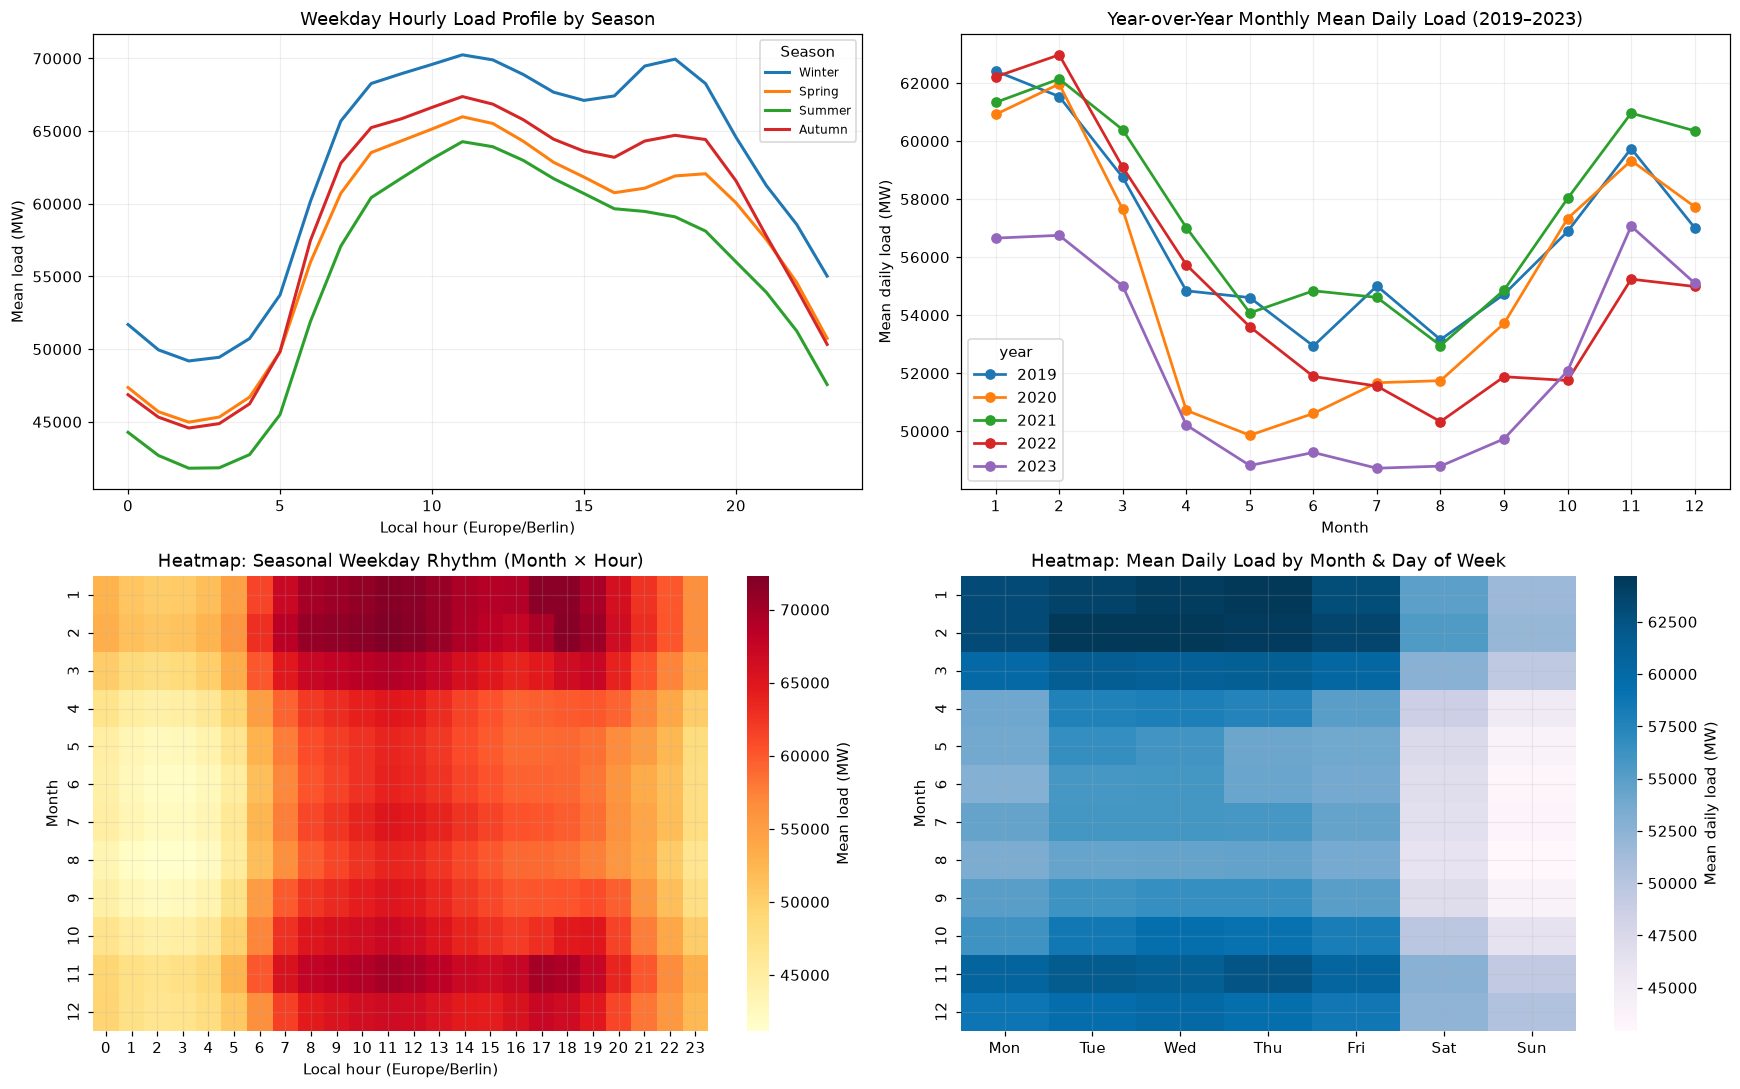

In [8]:
wd_h = hourly.loc[hourly["day_type"] == "Weekday"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Weekday hourly profile by season
wd_h.groupby(["hour", "season"])["average_load_mw"].mean().unstack()[SEASON_ORDER].plot(
    ax=axes[0, 0], lw=2
)
axes[0, 0].set_title("Weekday Hourly Load Profile by Season")
axes[0, 0].set_xlabel("Local hour (Europe/Berlin)")
axes[0, 0].set_ylabel("Mean load (MW)")
axes[0, 0].legend(title="Season", fontsize=8)

# 2. Year-over-year monthly mean daily load
daily.pivot_table(index="month", columns="year", values="average_load_mw", aggfunc="mean").plot(
    ax=axes[0, 1], marker="o", lw=1.8
)
axes[0, 1].set_title("Year-over-Year Monthly Mean Daily Load (2019–2023)")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Mean daily load (MW)")
axes[0, 1].set_xticks(range(1, 13))

# 3. Heatmap: Month x Hour of Day (Weekdays)
hm_month = wd_h.pivot_table(index="month", columns="hour", values="average_load_mw", aggfunc="mean")
sns.heatmap(hm_month, cmap="YlOrRd", ax=axes[1, 0], cbar_kws={"label": "Mean load (MW)"})
axes[1, 0].set_title("Heatmap: Seasonal Weekday Rhythm (Month × Hour)")
axes[1, 0].set_xlabel("Local hour (Europe/Berlin)")
axes[1, 0].set_ylabel("Month")

# 4. Heatmap: Month x Day of Week (Daily Load)
hm_dow_m = daily.pivot_table(
    index="month", columns="weekday", values="average_load_mw", aggfunc="mean"
)
hm_dow_m.columns = weekday_labels
sns.heatmap(hm_dow_m, cmap="PuBu", ax=axes[1, 1], cbar_kws={"label": "Mean daily load (MW)"})
axes[1, 1].set_title("Heatmap: Mean Daily Load by Month & Day of Week")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Month")

plt.tight_layout()
plt.show()

## Phase 5 — Decomposition

`Observed daily load = trend + weekly seasonality + annual seasonality + remainder`

MSTL uses periods of 7 and 365 days. Robust fitting reduces the influence of extremes without removing observations.

- Weekly plot: first eight weeks of 2023. Other plots: 2019–2023.
- Annual cycle is approximate: leap years and moving holidays are not explicitly modeled.
- Remainder: variation not explained by the components; not necessarily data errors.
- This is retrospective analysis, not a forecasting model. Edge estimates are less reliable.

Component sum matches observed load.


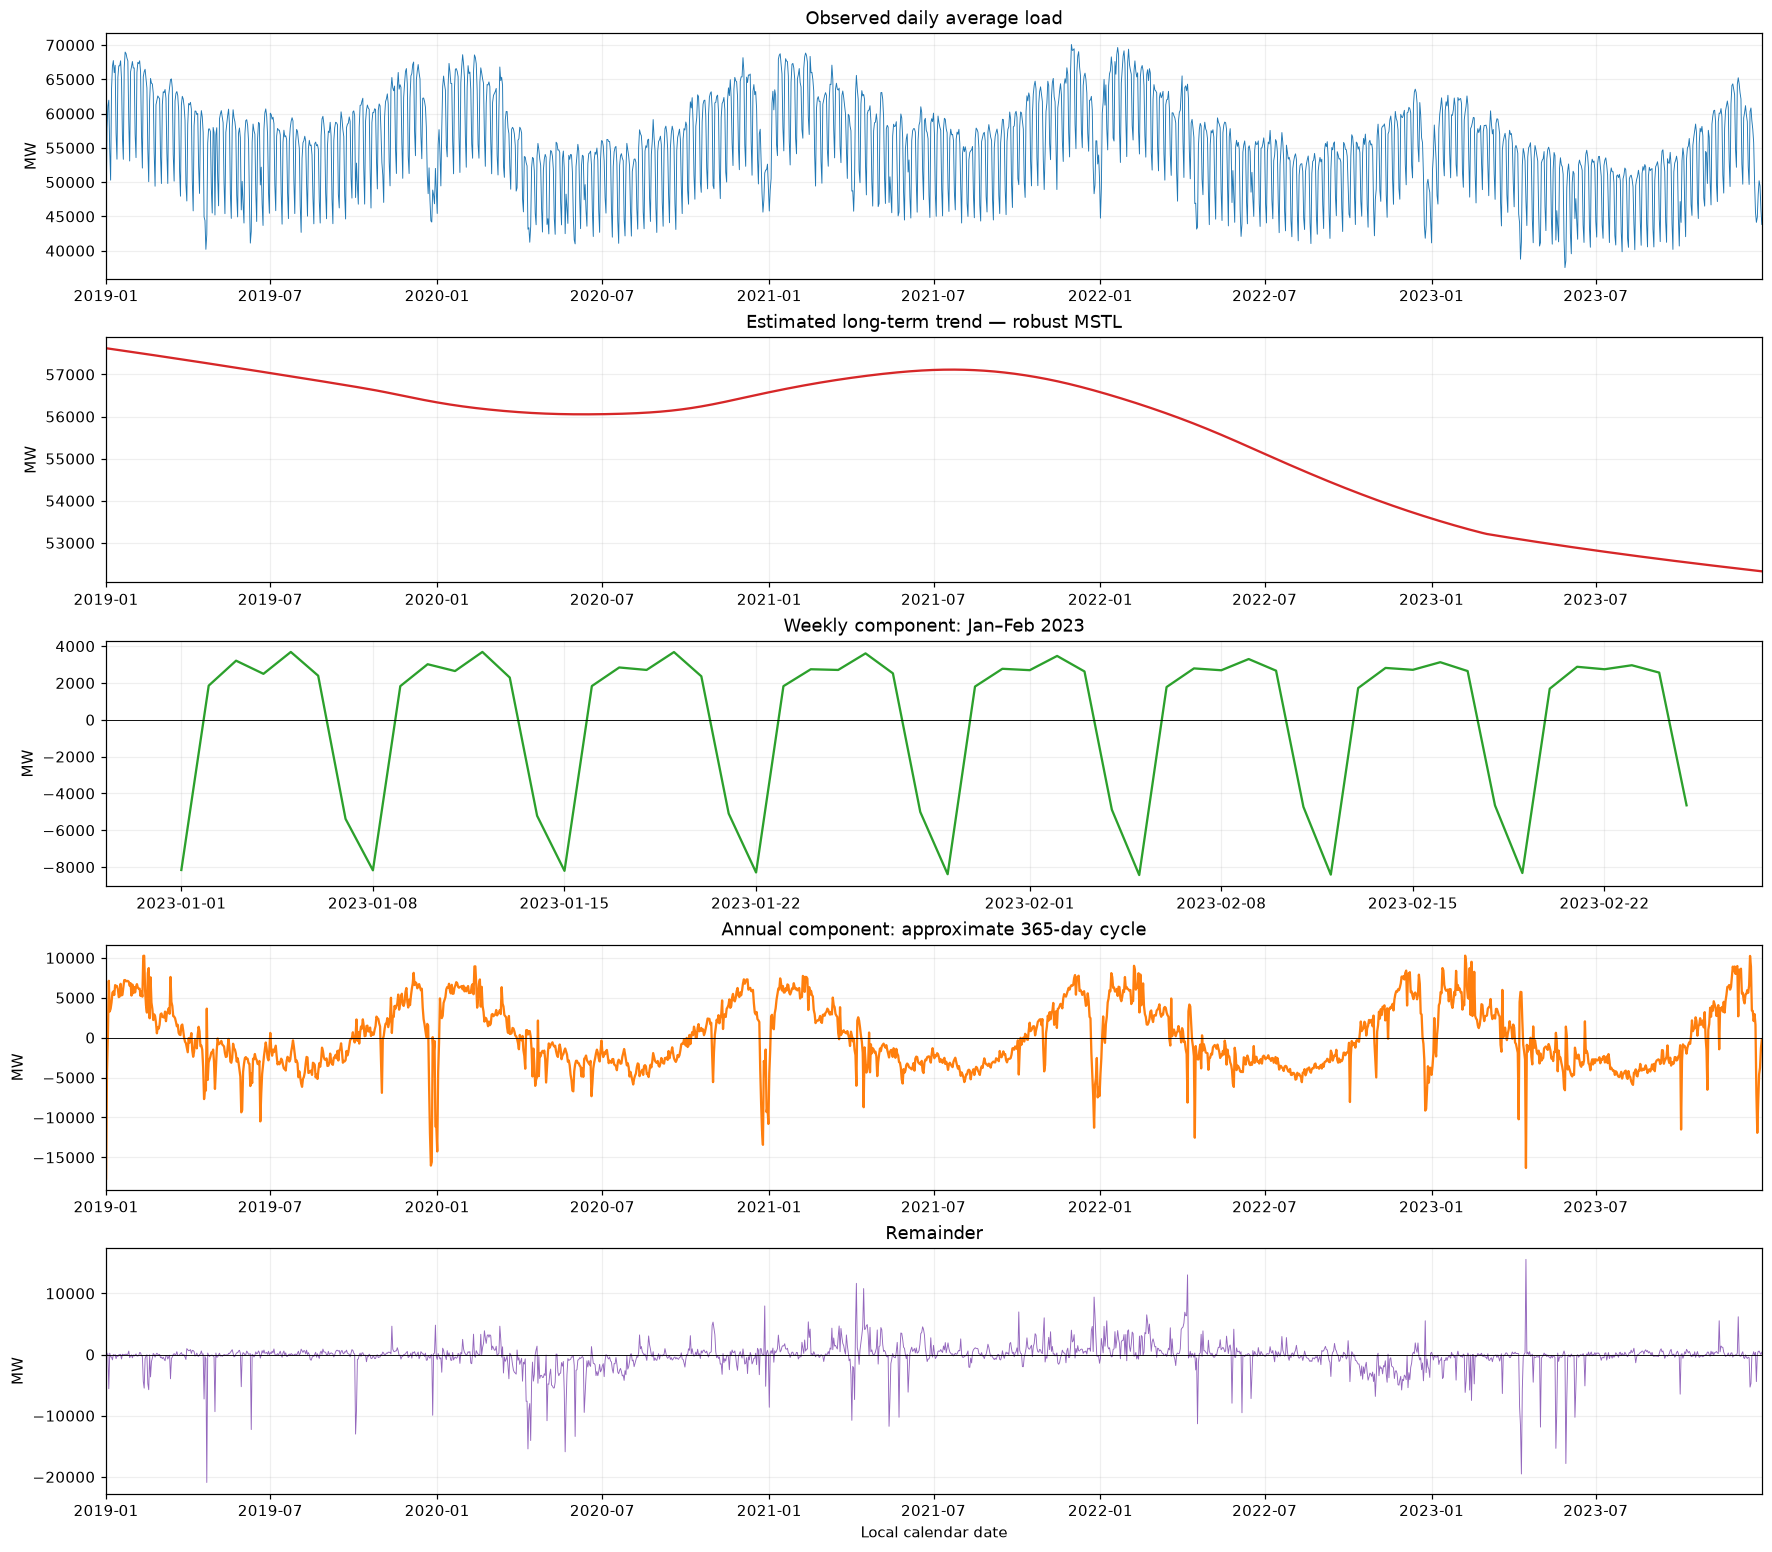

,mean_observed_mw,mean_trend_mw,remainder_std_mw
year,,,
2019,56776.92,57016.60,1921.76
2020,55254.67,56184.59,2573.83
2021,57603.10,56924.64,2201.44
2022,55057.19,55099.56,2393.69
2023,52326.58,52848.73,2498.83


In [9]:
from statsmodels.tsa.seasonal import MSTL

seasonal_fit = MSTL(daily_load, periods=(7, 365), stl_kwargs={"robust": True}).fit()
seasonal_components = seasonal_fit.seasonal
if not isinstance(seasonal_components, pd.DataFrame) or seasonal_components.shape[1] != 2:
    raise ValueError("Expected both weekly and annual seasonal components.")
decomposition = pd.DataFrame(
    {
        "observed_mw": daily_load,
        "trend_mw": seasonal_fit.trend,
        "weekly_mw": seasonal_components.iloc[:, 0],
        "annual_mw": seasonal_components.iloc[:, 1],
        "remainder_mw": seasonal_fit.resid,
    }
)
reconstructed_load = decomposition[["trend_mw", "weekly_mw", "annual_mw", "remainder_mw"]].sum(
    axis=1
)
np.testing.assert_allclose(reconstructed_load, daily_load, rtol=1e-10, atol=1e-8)
print("Component sum matches observed load.")

fig, axes = plt.subplots(5, 1, figsize=(16, 14), constrained_layout=True)
axes[0].plot(decomposition.index, decomposition.observed_mw, linewidth=0.6)
axes[0].set(title="Observed daily average load", ylabel="MW")
axes[1].plot(decomposition.index, decomposition.trend_mw, color="tab:red")
axes[1].set(title="Estimated long-term trend — robust MSTL", ylabel="MW")
weekly_zoom = decomposition.loc["2023-01-01":"2023-02-25", "weekly_mw"]
axes[2].plot(weekly_zoom.index, weekly_zoom, color="tab:green")
axes[2].set(title="Weekly component: Jan–Feb 2023", ylabel="MW")
axes[3].plot(decomposition.index, decomposition.annual_mw, color="tab:orange")
axes[3].set(title="Annual component: approximate 365-day cycle", ylabel="MW")
axes[4].plot(decomposition.index, decomposition.remainder_mw, linewidth=0.6, color="tab:purple")
axes[4].set(title="Remainder", xlabel="Local calendar date", ylabel="MW")
for ax in axes[2:]:
    ax.axhline(0, color="black", linewidth=0.6)
for ax in [axes[0], axes[1], axes[3], axes[4]]:
    ax.set_xlim(daily_load.index.min(), daily_load.index.max())
plt.show()

decomposition_yearly = (
    decomposition.assign(year=decomposition.index.year)
    .groupby("year")
    .agg(
        mean_observed_mw=("observed_mw", "mean"),
        mean_trend_mw=("trend_mw", "mean"),
        remainder_std_mw=("remainder_mw", "std"),
    )
)
display(decomposition_yearly.round(2))

### Findings

- Load is lower overnight and on weekends; higher on weekday daytime hours.
- Winter months generally have higher relative load than summer months.
- Mean daily load: 56,777 MW in 2019 and 52,327 MW in 2023, with a rebound in 2021.
- Year-on-year change: −4.42% in 2022 and −4.96% in 2023.
- MSTL estimates a declining trend after 2021. Causes have not been established.